# 3. Alur 2 model: foto wajah → kotak jerawat → jenis

Sama dengan yang dilakukan aplikasi (`app/app.py`), memakai `src/pipeline.py`:
1. **Model 1** mencari kotak jerawat.
2. Tiap kotak **dipotong** (pas kotak, sama seperti data latih model 2).
3. Potongan diubah jadi **60 ciri**, lalu **model 2** menebak jenisnya.

*Bukan alat diagnosis medis.*

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
while not (ROOT / 'models').exists() or not (ROOT / 'data').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Jalankan notebook dari dalam folder proyek FINAL')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
DATA = ROOT / 'data'
print('folder proyek:', ROOT)

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

import pipeline

detektor = pipeline.muat_deteksi()
model, kelas = pipeline.muat_jenis()
WARNA = {'Blackheads': (40, 40, 40), 'Cyst': (148, 0, 211), 'Papules': (230, 30, 30), 'Pustules': (255, 200, 0), 'Whiteheads': (0, 170, 255)}

folder proyek: C:\Users\wibya\CAWU 4\PROJECT AI - JERAWAT FINAL


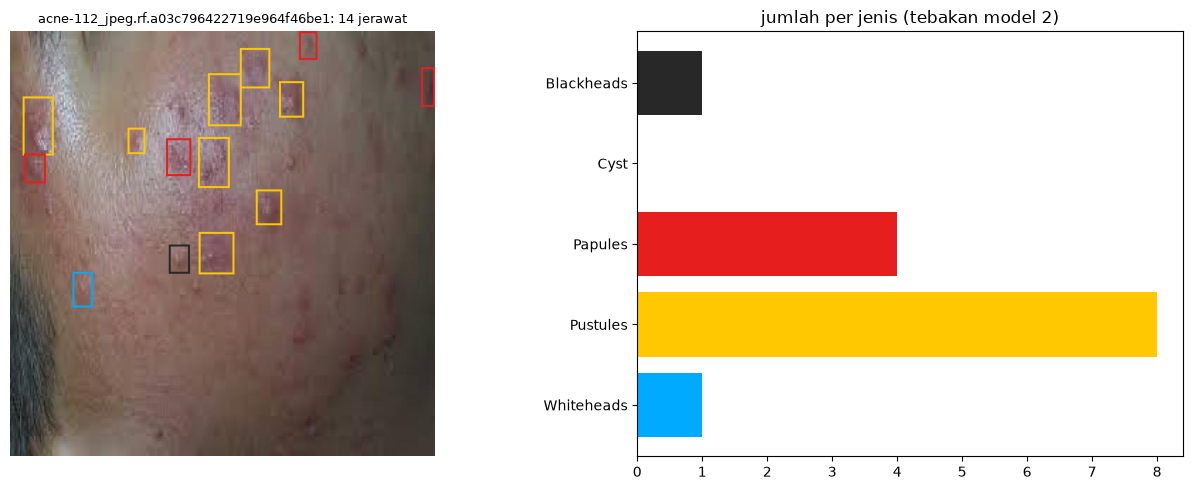

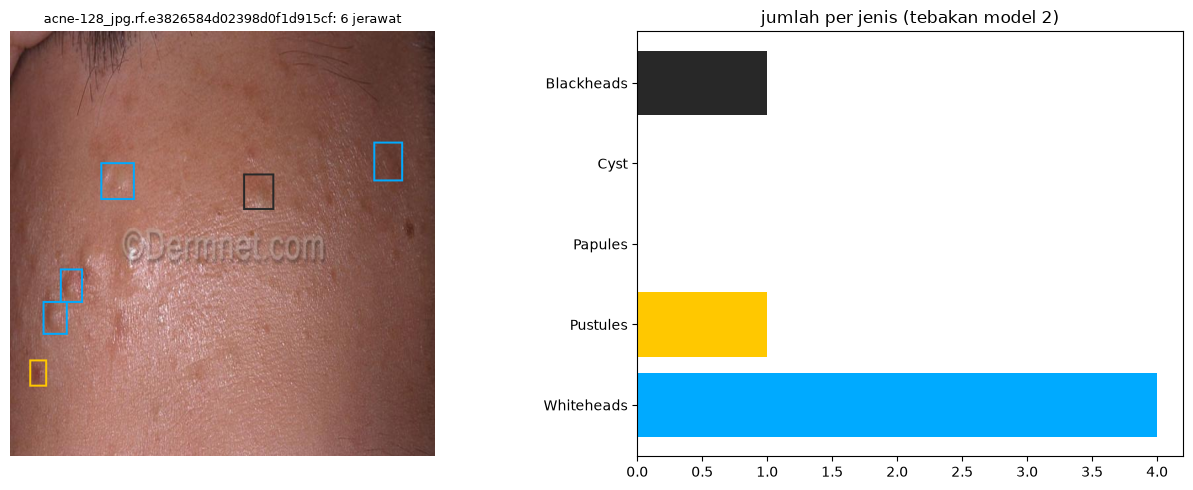

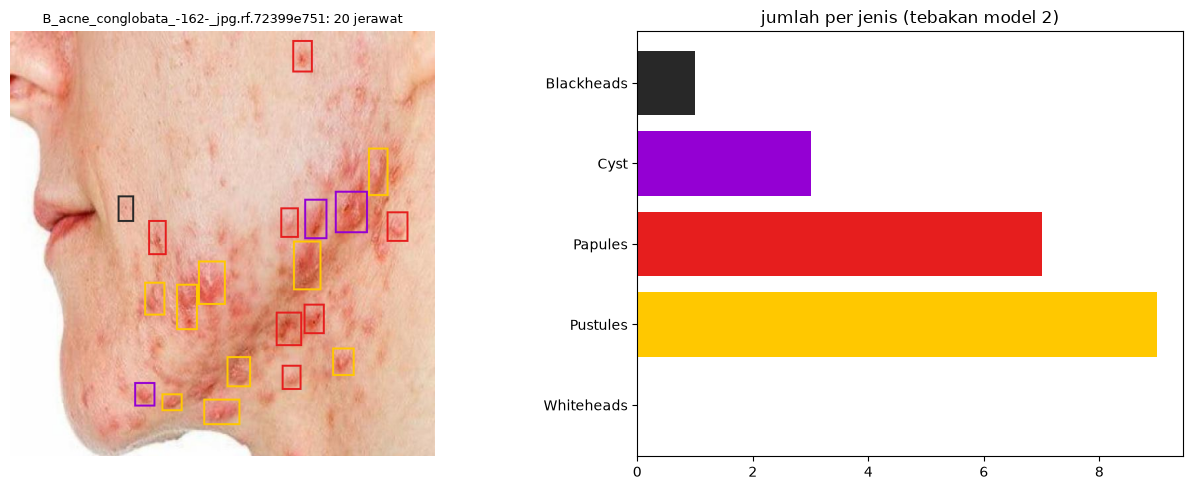

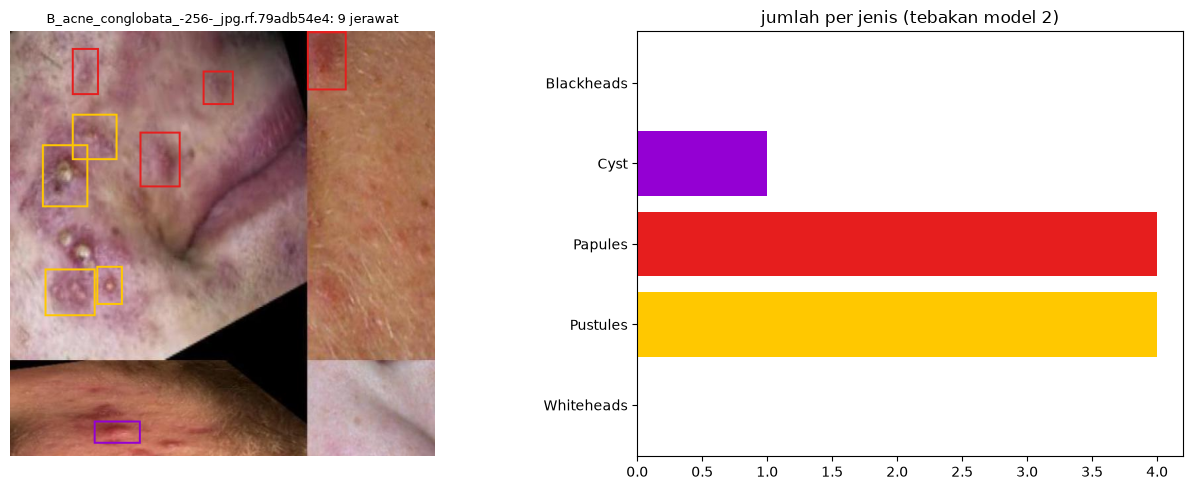

Bukan alat diagnosis medis.


In [2]:
contoh = sorted((DATA / 'deteksi' / 'test' / 'images').glob('*'))[2:4] + sorted((DATA / 'deteksi_bh' / 'test' / 'images').glob('*'))[2:4]
for g in contoh:
    foto = Image.open(g).convert('RGB')
    hasil = pipeline.jalankan(foto, detektor, model, kelas, conf=0.25, iou=0.45)
    out = foto.copy(); dr = ImageDraw.Draw(out)
    for h in hasil:
        dr.rectangle(h['kotak'], outline=WARNA[h['jenis']], width=3)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [3, 2]})
    ax[0].imshow(out); ax[0].axis('off'); ax[0].set_title(f'{g.name[:40]}: {len(hasil)} jerawat', fontsize=9)
    jumlah = {k: sum(h['jenis'] == k for h in hasil) for k in WARNA}
    ax[1].barh(list(jumlah), list(jumlah.values()), color=[tuple(c / 255 for c in WARNA[k]) for k in jumlah])
    ax[1].invert_yaxis(); ax[1].set_title('jumlah per jenis (tebakan model 2)')
    plt.tight_layout(); plt.show()
print('Bukan alat diagnosis medis.')